<div style="background-color:#EFF5FF; padding:14px; border-radius:10px; border-left:8px solid #009E91;">

<h2 style="margin-bottom:0;"><b>Notebook 3: Vectorization and Modelling</b></h2>

# Table of Contents: Notebook 3 - Feature Engineering & Predictive Modeling

**1. Introduction**
*(O texto introdutório que já criámos na resposta anterior)*

**2. Feature Extraction (Vectorization)**
*(Aqui aplicamos a matéria do Notebook 3 do teu professor, testando os dois métodos e usando Unigramas e Bigramas)*
* 2.1. Vectorizing with Bag-of-Words (CountVectorizer)
* 2.2. Vectorizing with Term Frequency-Inverse Document Frequency (TF-IDF)
* 2.3. Vector Spaces Comparison (BoW vs. TF-IDF)

**3. Data Splitting & Handling Class Imbalance**
*(Aqui resolvemos o problema da Pop dominar o dataset)*
* 3.1. Train/Test Split
* 3.2. Addressing Imbalance (SMOTE / Class Weights / Undersampling)

**4. Predictive Modeling (Machine Learning)**
*(Onde os modelos tentam adivinhar o género musical)*
* 4.1. Baseline Model: Multinomial Naive Bayes
* 4.2. Advanced Model 1: Logistic Regression 
* 4.3. Advanced Model 2: Support Vector Machines (SVM) / Random Forest

**5. Model Evaluation & Comparison**
*(Avaliação baseada no que discutiste: evitar Accuracy cega)*
* 5.1. Classification Reports (Precision, Recall, Macro F1-Score)
* 5.2. Confusion Matrices Analysis (Genre-by-Genre Performance)

**6. Conclusion & Best Model Selection**



### **1. Introduction, Imports and Libraries**

In the previous notebook, we focused entirely on preparing our dataset. **We are now ready to transition into the machine learning phase**.

The first major challenge in this notebook is feature engineering. Since machine learning algorithms **cannot interpret raw text, we need to translate our processed lyrics into a mathematical format**. To achieve this, we will apply vectorization techniques, primarily **TF-IDF** (Term Frequency-Inverse Document Frequency), which will assign numerical weights to words based on their importance and rarity across the different musical genres.

After vectorizing the text, we will address the significant class imbalance we identified during the Exploratory Data Analysis. We will explore strategies such as class weights or resampling to create a more balanced learning environment. Finally, we will **train several classification models and evaluate their performance** using robust metrics like Precision, Recall, and the Macro F1-Score, ensuring our models can accurately predict genres across the entire musical spectrum.

In [37]:
import pickle

with open('train_dataset_preprocessed.pkl', 'rb') as f:
    train_dataset = pickle.load(f)

In [40]:
import re
import os
import pickle
import nltk

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from collections import defaultdict
from collections import Counter

import matplotlib.colors as mcolors
from wordcloud import WordCloud

In [12]:
# Exemplo de como aplicas a função atualizada no teu Notebook de limpeza:
from utils.processing_pipeline_for_classification import tokenization_processing


train_dataset['lyrics_processed_for_classification'] = train_dataset['lyrics_processed_for_classification'].apply(
    lambda text: tokenization_processing(
        text, 
        print_output=False, 
        pos_tagging=True, 
        no_stopwords=True, 
        lemmatized=True,
        tokenized_output=False 
    )
)

TypeError: expected string or bytes-like object, got 'tuple'

### **Bag of words**

In [41]:
# o que o stor
bow_vectorizer = CountVectorizer(ngram_range=(1,2), token_pattern=r"(?u)\b\w+\b")
tfidf_vectorizer = TfidfVectorizer(ngram_range=(1,2), token_pattern=r"(?u)\b\w+\b")

In [ ]:
import ast
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# 1. Função para extrair e juntar as palavras numa única string de texto
def join_tokens_for_sklearn(val):
    if isinstance(val, str):
        try:
            val = ast.literal_eval(val)
        except:
            pass
            
    if isinstance(val, tuple):
        val = val[0] 
        
    words = []
    if isinstance(val, list):
        for x in val:
            if isinstance(x, (list, tuple)):
                words.append(str(x[0]))
            else:
                words.append(str(x))
                
    return " ".join(words)

# 2. Criar a coluna temporária perfeita para o Scikit-Learn
print("A preparar o texto para o Scikit-Learn...")
train_dataset["text_for_sklearn"] = train_dataset["lyrics_processed_for_classification"].dropna().apply(join_tokens_for_sklearn)

# 3. Inicializar os vetorizadores COM limites para não esgotar a RAM (max_features=10000 e min_df=5)
print("A inicializar os vetorizadores...")
bow_vectorizer = CountVectorizer(ngram_range=(1,2), token_pattern=r"(?u)\b\w+\b", min_df=5, max_features=10000)
tfidf_vectorizer = TfidfVectorizer(ngram_range=(1,2), token_pattern=r"(?u)\b\w+\b", min_df=5, max_features=10000)

# 4. Criar as Matrizes Esparsas (Atenção: SEM usar .toarray() nem guardar dentro do Pandas!)
print("A criar a matriz BoW...")
bow_matrix = bow_vectorizer.fit_transform(train_dataset["text_for_sklearn"].dropna())

print("A criar a matriz TF-IDF...")
tfidf_matrix = tfidf_vectorizer.fit_transform(train_dataset["text_for_sklearn"].dropna())

# 5. Guardar os nomes das palavras/bigramas (vocabulario)
bow_word_list = bow_vectorizer.get_feature_names_out()
tfidf_word_list = tfidf_vectorizer.get_feature_names_out()

# Confirmar que funcionou e ver o tamanho real
print("\nConcluído com sucesso!")
print(f"Formato da matriz BoW: {bow_matrix.shape}")
print(f"Formato da matriz TF-IDF: {tfidf_matrix.shape}")

A preparar o texto para o Scikit-Learn...
A inicializar os vetorizadores...
A criar a matriz BoW...


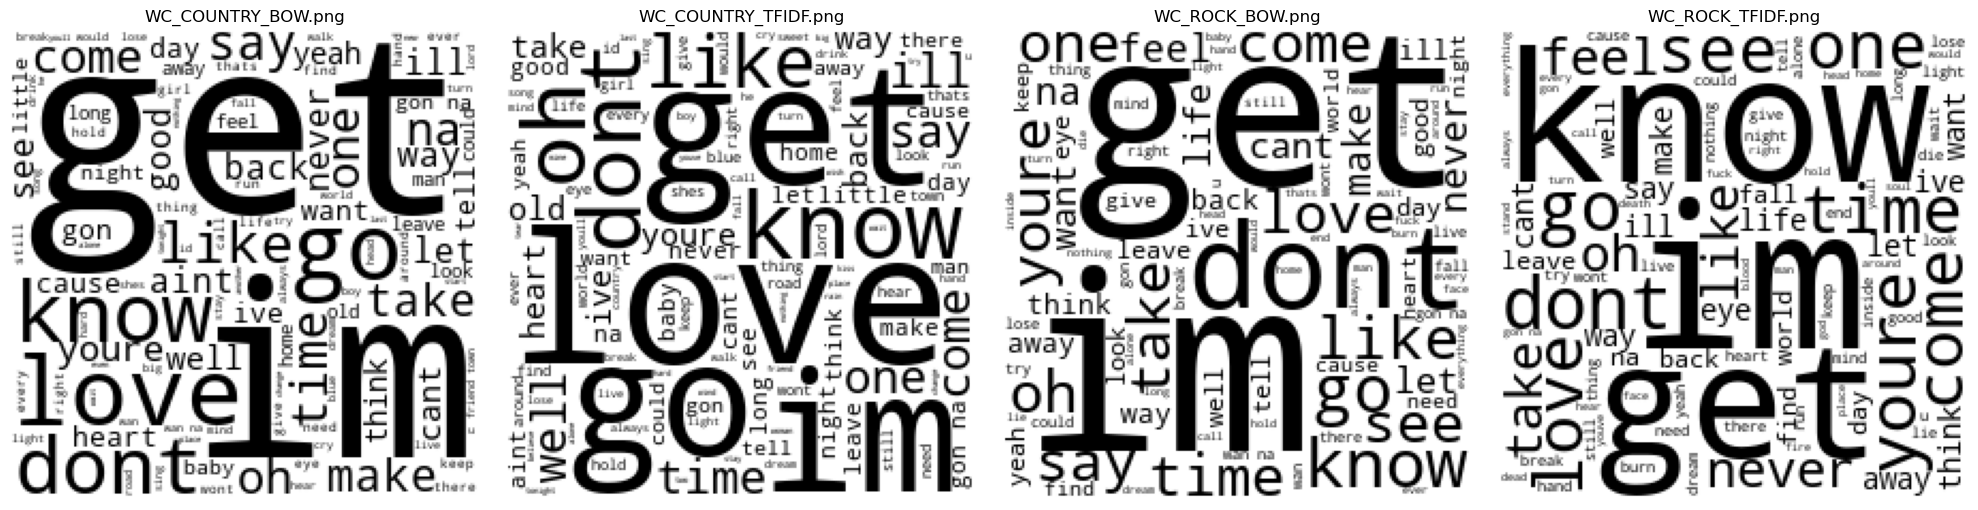

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from wordcloud import WordCloud

# 1. A função adaptada (mantém a lógica do professor, mas itera por Género)
def genre_word_cloud_generator(folder_path, dataset, matrix, word_list, wc, vectorisation="bow", prefix="WC_"):
    """Save one word cloud per genre, from its BoW counts or its TF-IDF weights."""

    if not os.path.exists(folder_path):
        os.makedirs(folder_path)

    genres = dataset['tag'].unique()
    
    for genre in genres:
        # Extração otimizada dos pesos matemáticos para substituir o 'word_freq_calculator'
        genre_indices = dataset[dataset['tag'] == genre].index
        sub_matrix = matrix[genre_indices]
        mean_weights = np.asarray(sub_matrix.mean(axis=0)).flatten()
        
        # Criação do dicionário {termo: peso} que a wordcloud exige
        genre_dict = dict(zip(word_list, mean_weights))

        # Gerar a nuvem de palavras
        wc.generate_from_frequencies(genre_dict)
        
        # Guardar a imagem (ex: WC_RAP_BOW.png)
        file_name = f"{prefix}{genre.upper()}_{vectorisation.upper()}.png"
        wc.to_file(os.path.join(folder_path, file_name))

# 2. A função do professor para mostrar as imagens lado a lado
def show_saved_images(file_names, folder_path="genre_word_clouds", panel_size=5):
    """Show saved images side by side, one panel per file, titled with its file name."""
    fig, axes = plt.subplots(1, len(file_names), figsize=(panel_size * len(file_names), panel_size))
    for ax, file_name in zip(axes, file_names):
        ax.imshow(plt.imread(os.path.join(folder_path, file_name)))
        ax.set_title(file_name)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

# -------------------------------------------------------------------------
# CÓDIGO DE EXECUÇÃO (IDÊNTICO AO DO PROFESSOR)
# -------------------------------------------------------------------------

# color_func returns black for every word, so font size is the only encoding.
# random_state=33 fixes the layout, so a chapter's clouds in later tasks differ only in colour.
wc = WordCloud(
    background_color="white",
    max_words=120, 
    width=220, 
    height=220, 
    color_func=lambda *args, **kwargs: (0,0,0), 
    random_state=33
)

# One image per genre and method in genre_word_clouds/, each name starting with WC_.
genre_word_cloud_generator("genre_word_clouds", train_dataset, bow_matrix, bow_word_list, wc, "bow")

genre_word_cloud_generator("genre_word_clouds", train_dataset, tfidf_matrix, tfidf_word_list, wc, "tfidf")

# Mostrar lado a lado (exemplo para o género RAP, podes mudar para COUNTRY, ROCK, etc.)
show_saved_images(["WC_COUNTRY_BOW.png", "WC_COUNTRY_TFIDF.png", "WC_ROCK_BOW.png", "WC_ROCK_TFIDF.png"], panel_size=5)

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from collections import defaultdict, Counter
from tqdm import tqdm

def plot_genre_cooccurrence(genre_name, dataset, top_n=80):
    """
    Gera a matriz de co-ocorrência e o Heatmap igual ao do professor, 
    mas otimizado para as top N palavras de um género musical.
    """
    print(f"A preparar dados para o género: {genre_name.upper()}...")
    
    # 1. Extrair os textos apenas das músicas deste género
    # (Usamos a coluna 'text_for_sklearn' que criámos antes e dividimos por espaços)
    genre_texts = dataset[dataset['tag'] == genre_name]['text_for_sklearn'].dropna().tolist()
    preproc_sentences = [text.split() for text in genre_texts]
    
    # 2. Descobrir as top_n palavras deste género para evitar MemoryErrors
    all_words = [word for sentence in preproc_sentences for word in sentence]
    top_words = [word for word, count in Counter(all_words).most_common(top_n)]
    top_words_set = set(top_words) # Convertido para 'set' para a pesquisa ser super rápida
    
    # 3. LÓGICA DO PROFESSOR: cooccurrence_matrix_sentence_generator
    co_occurrences = defaultdict(Counter)
    
    # tqdm mostra a barra de progresso tal como o professor tinha
    for sentence in tqdm(preproc_sentences, desc="A calcular co-ocorrências"):
        # Filtramos a frase para conter apenas palavras do Top N
        filtered_sentence = [w for w in sentence if w in top_words_set]
        
        for i, token_1 in enumerate(filtered_sentence):
            for j, token_2 in enumerate(filtered_sentence):
                if token_1 != token_2:
                    co_occurrences[token_1][token_2] += 1
                    
    # 4. Inicializar e preencher a matriz densa (numpy)
    co_matrix = np.zeros((len(top_words), len(top_words)), dtype=int)
    word_index = {word: idx for idx, word in enumerate(top_words)}
    
    for word, neighbors in co_occurrences.items():
        for neighbor, count in neighbors.items():
            co_matrix[word_index[word]][word_index[neighbor]] = count
            
    # Criar o DataFrame para melhor legibilidade
    co_matrix_df = pd.DataFrame(co_matrix, index=top_words, columns=top_words)
    
    # Ordenar pelas palavras que mais co-ocorrem (código do professor)
    co_matrix_df = co_matrix_df.reindex(co_matrix_df.sum().sort_values(ascending=False).index, axis=1)
    co_matrix_df = co_matrix_df.reindex(co_matrix_df.sum().sort_values(ascending=False).index, axis=0)
    
    # 5. GERAR O HEATMAP (Exatamente igual à imagem do stor)
    # Criar máscara para o triângulo superior
    mask = np.triu(np.ones_like(co_matrix_df, dtype=bool))
    
    plt.figure(figsize=(20, 20))
    # sns.heatmap com a paleta Greens e a mask do professor
    sns.heatmap(co_matrix_df, cmap="Greens", mask=mask, annot=False, norm=mcolors.LogNorm())
    plt.title(f"Co-occurrence Matrix Heatmap: {genre_name.upper()} (Top {top_n} Words)", fontsize=20, fontweight='bold')
    plt.show()
    
    return co_matrix_df

# Testa para o Rap (ou muda para 'country', 'rock', etc.)
# Só precisas de correr isto no Notebook 3!
matriz_rap = plot_genre_cooccurrence(genre_name='misc', dataset=train_dataset, top_n=80)

A preparar dados para o género: POP...


KeyError: 'text_for_sklearn'